In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Laptop.csv', encoding='latin1')

In [3]:
df

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target)
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1316,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,638.00
1299,1317,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,1499.00
1300,1318,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,229.00
1301,1319,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,764.00


In [4]:
df.shape

(1303, 13)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1303 non-null   int64  
 1   Company               1303 non-null   str    
 2   Product               1303 non-null   str    
 3   TypeName              1303 non-null   str    
 4   Inches                1303 non-null   float64
 5   ScreenResolution      1303 non-null   str    
 6   Cpu                   1303 non-null   str    
 7   Ram                   1303 non-null   str    
 8   Memory                1303 non-null   str    
 9   Gpu                   1303 non-null   str    
 10  OpSys                 1303 non-null   str    
 11  Weight                1303 non-null   str    
 12  Price_euros (Target)  1303 non-null   float64
dtypes: float64(2), int64(1), str(10)
memory usage: 132.5 KB


# Data Cleaning Process:

In [6]:
df.duplicated().sum() #to ensure no duplicate row is present

np.int64(0)

In [7]:
df.isnull().sum()

laptop_ID               0
Company                 0
Product                 0
TypeName                0
Inches                  0
ScreenResolution        0
Cpu                     0
Ram                     0
Memory                  0
Gpu                     0
OpSys                   0
Weight                  0
Price_euros (Target)    0
dtype: int64

In [8]:
df['Ram'].str.replace('GB','') #removing GB from RAM column

0        8
1        8
2        8
3       16
4        8
        ..
1298     4
1299    16
1300     2
1301     6
1302     4
Name: Ram, Length: 1303, dtype: str

In [9]:
df['Weight'] = df['Weight'].str.replace('kg','') #removing kg from weight column

In [10]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target)
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60


In [11]:
# Handle missing values in 'Ram' before conversion
df['Ram'] = df['Ram'].astype(str).str.replace('GB', '')
df['Ram'] = pd.to_numeric(df['Ram'], errors='coerce').fillna(0).astype(int)

# Convert Weight to float
df['Weight'] = pd.to_numeric(df['Weight'], errors='coerce').fillna(0).astype(float)


In [12]:
print(df['Ram'].head())
print(df['Weight'].head())


0     8
1     8
2     8
3    16
4     8
Name: Ram, dtype: int64
0    1.37
1    1.34
2    1.86
3    1.83
4    1.37
Name: Weight, dtype: float64


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1303 non-null   int64  
 1   Company               1303 non-null   str    
 2   Product               1303 non-null   str    
 3   TypeName              1303 non-null   str    
 4   Inches                1303 non-null   float64
 5   ScreenResolution      1303 non-null   str    
 6   Cpu                   1303 non-null   str    
 7   Ram                   1303 non-null   int64  
 8   Memory                1303 non-null   str    
 9   Gpu                   1303 non-null   str    
 10  OpSys                 1303 non-null   str    
 11  Weight                1303 non-null   float64
 12  Price_euros (Target)  1303 non-null   float64
dtypes: float64(3), int64(2), str(8)
memory usage: 132.5 KB


C:\Users\pc\AppData\Local\Temp\ipykernel_19312\1093788652.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Price_euros (Target)'])


<Axes: xlabel='Price_euros (Target)', ylabel='Density'>

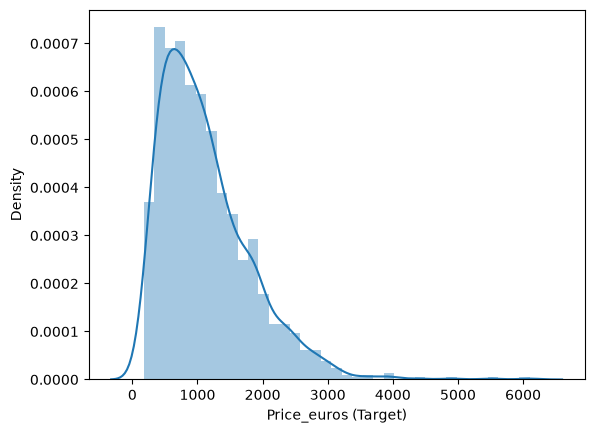

In [14]:
sns.distplot(df['Price_euros (Target)'])

<Axes: xlabel='Company'>

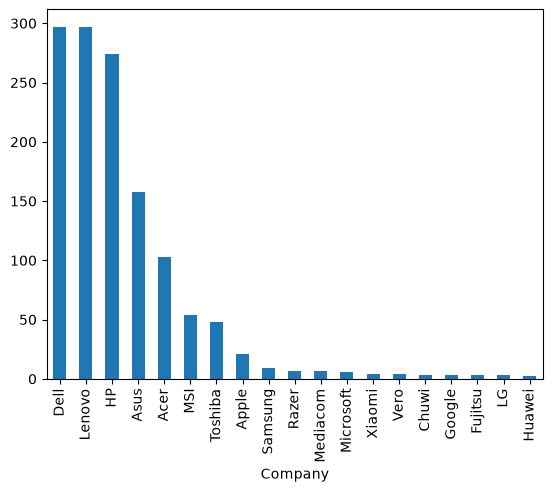

In [15]:
df['Company'].value_counts().plot(kind='bar')

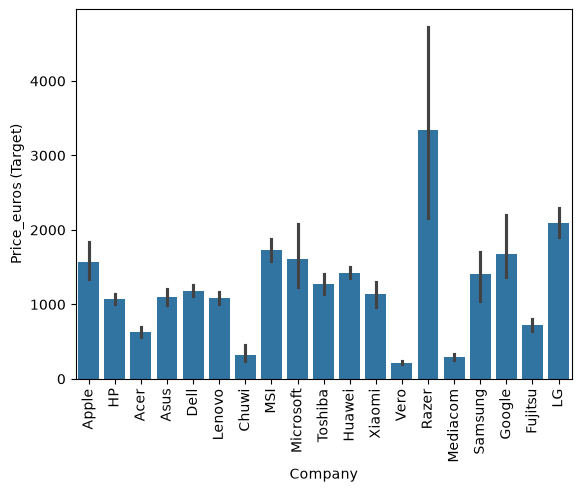

In [16]:
sns.barplot(x=df['Company'], y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')  # Rotate x-axis labels for better readability
plt.show()

<Axes: xlabel='TypeName'>

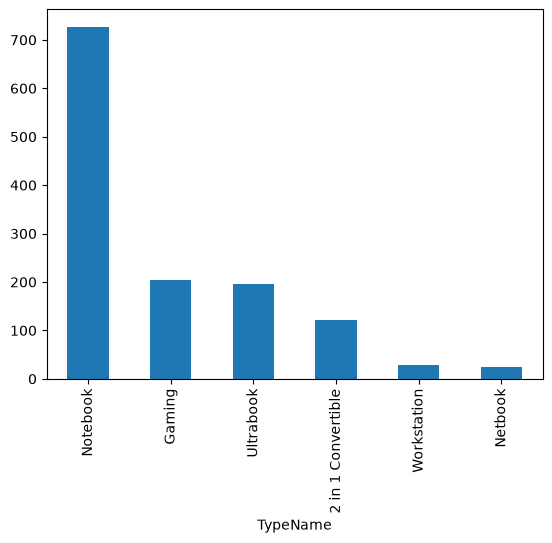

In [17]:
df['TypeName'].value_counts().plot(kind='bar')

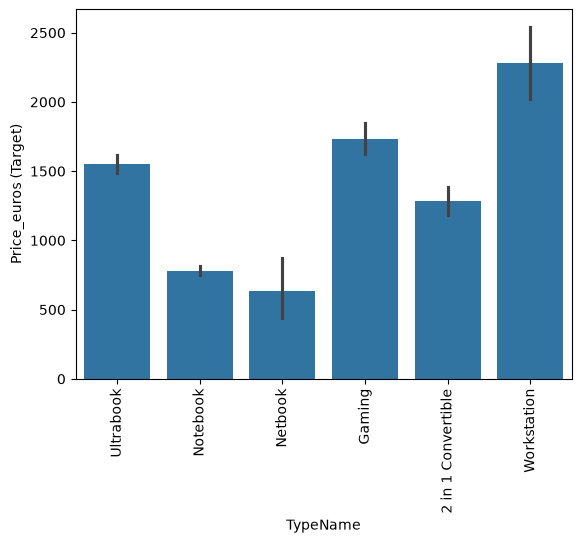

In [18]:
sns.barplot(x=df['TypeName'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

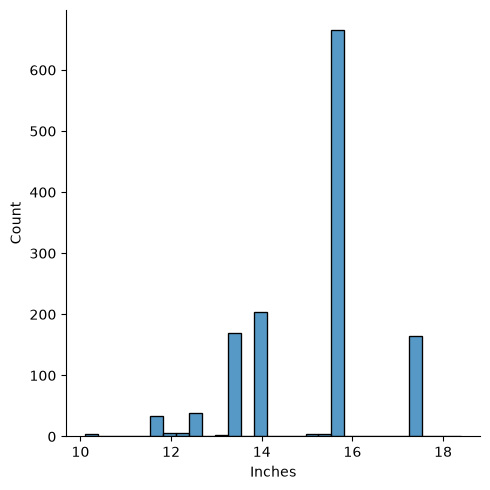

In [19]:
sns.displot(df['Inches'])

<Axes: xlabel='Inches', ylabel='Price_euros (Target)'>

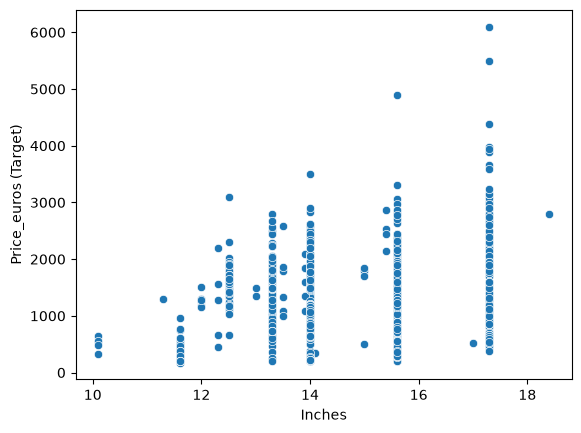

In [20]:
sns.scatterplot(x=df['Inches'],y=df['Price_euros (Target)'])

In [21]:
df['ScreenResolution'].value_counts()

ScreenResolution
Full HD 1920x1080                                507
1366x768                                         281
IPS Panel Full HD 1920x1080                      230
IPS Panel Full HD / Touchscreen 1920x1080         53
Full HD / Touchscreen 1920x1080                   47
1600x900                                          23
Touchscreen 1366x768                              16
Quad HD+ / Touchscreen 3200x1800                  15
IPS Panel 4K Ultra HD 3840x2160                   12
IPS Panel 4K Ultra HD / Touchscreen 3840x2160     11
4K Ultra HD / Touchscreen 3840x2160               10
IPS Panel 1366x768                                 7
Touchscreen 2560x1440                              7
4K Ultra HD 3840x2160                              7
IPS Panel Retina Display 2560x1600                 6
IPS Panel Retina Display 2304x1440                 6
Touchscreen 2256x1504                              6
IPS Panel Quad HD+ / Touchscreen 3200x1800         6
IPS Panel Touchscreen 2560x14

In [22]:
df['Touchscreen'] = df['ScreenResolution'].apply(lambda x: 1 if 'Touchscreen' in x else 0)


In [23]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0


<Axes: xlabel='Touchscreen'>

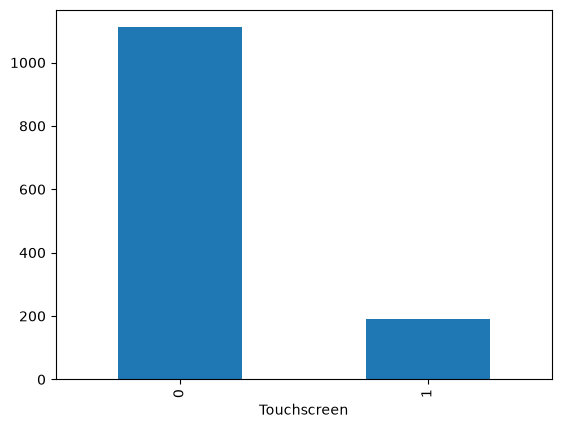

In [24]:
df['Touchscreen'].value_counts().plot(kind='bar')

<Axes: xlabel='Touchscreen', ylabel='Price_euros (Target)'>

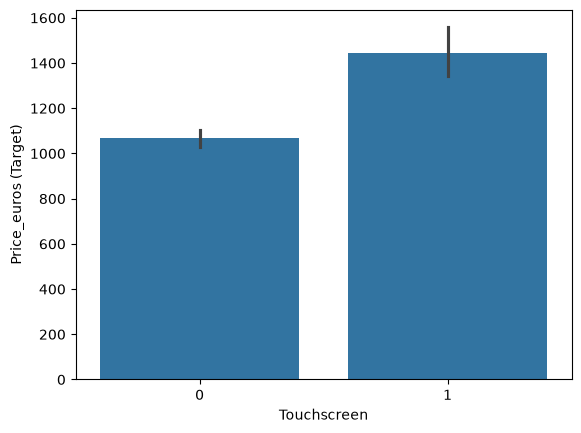

In [25]:
sns.barplot(x=df['Touchscreen'],y=df['Price_euros (Target)'])

In [26]:
df['Ips']=df['ScreenResolution'].apply(lambda x:1 if 'IPS' in x else 0)

<Axes: xlabel='Ips'>

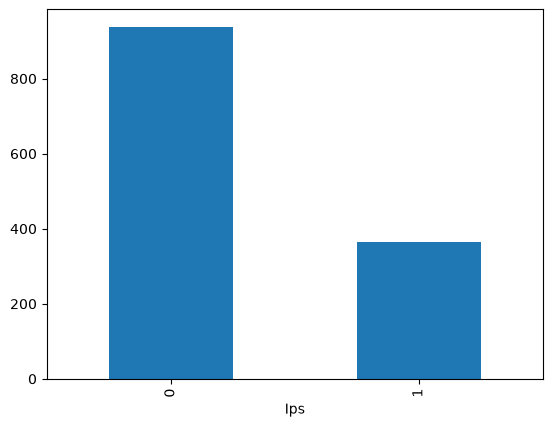

In [27]:
df['Ips'].value_counts().plot(kind='bar')

<Axes: xlabel='Ips', ylabel='Price_euros (Target)'>

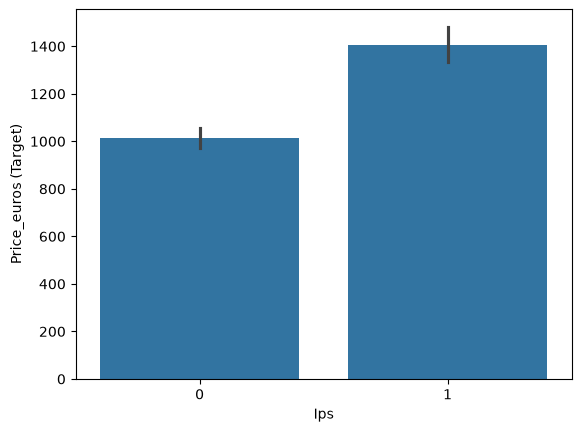

In [28]:
sns.barplot(x=df['Ips'],y=df['Price_euros (Target)'])

In [29]:
new=df['ScreenResolution'].str.split('x',n=1,expand=True)
new

,0,1
0,IPS Panel Retina Display 2560,1600
1,1440,900
2,Full HD 1920,1080
3,IPS Panel Retina Display 2880,1800
4,IPS Panel Retina Display 2560,1600
...,...,...
1298,IPS Panel Full HD / Touchscreen 1920,1080
1299,IPS Panel Quad HD+ / Touchscreen 3200,1800
1300,1366,768
1301,1366,768


In [30]:
df['X_res']=new[0]
df['Y_res']=new[1]

In [31]:
df.sample(5)

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,X_res,Y_res
745,753,Acer,Chromebook 14,Notebook,14.0,1366x768,Intel Celeron Dual Core N3060 1.6GHz,2,32GB Flash Storage,Intel HD Graphics 400,Chrome OS,1.68,330.0,0,0,1366,768
816,825,Razer,Blade Stealth,Ultrabook,12.5,IPS Panel 4K Ultra HD / Touchscreen 3840x2160,Intel Core i7 7500U 2.5GHz,16,512GB SSD,Intel HD Graphics 620,Windows 10,1.29,1799.0,1,1,IPS Panel 4K Ultra HD / Touchscreen 3840,2160
946,960,Dell,Latitude 7280,Ultrabook,12.5,Full HD / Touchscreen 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics,Windows 10,1.36,1472.2,1,0,Full HD / Touchscreen 1920,1080
442,449,Lenovo,ThinkPad X270,Ultrabook,12.5,IPS Panel Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,Windows 10,1.36,1429.0,0,1,IPS Panel Full HD 1920,1080
1199,1217,MSI,GS73VR 7RF,Gaming,17.3,Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1060,Windows 10,2.43,2048.9,0,0,Full HD 1920,1080


In [32]:
df['X_res']=df['X_res'].str.replace(',','').str.findall(r'(\d+\.?\d+)').apply(lambda 
                                                                              x:x[0])

In [33]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,X_res,Y_res
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,2560,1600
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,1440,900
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,1920,1080
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,2880,1800
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,2560,1600


In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1303 non-null   int64  
 1   Company               1303 non-null   str    
 2   Product               1303 non-null   str    
 3   TypeName              1303 non-null   str    
 4   Inches                1303 non-null   float64
 5   ScreenResolution      1303 non-null   str    
 6   Cpu                   1303 non-null   str    
 7   Ram                   1303 non-null   int64  
 8   Memory                1303 non-null   str    
 9   Gpu                   1303 non-null   str    
 10  OpSys                 1303 non-null   str    
 11  Weight                1303 non-null   float64
 12  Price_euros (Target)  1303 non-null   float64
 13  Touchscreen           1303 non-null   int64  
 14  Ips                   1303 non-null   int64  
 15  X_res                 1303 non-n

In [35]:
df['X_res']=df['X_res'].astype('int')
df['Y_res']=df['Y_res'].astype('int')

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1303 non-null   int64  
 1   Company               1303 non-null   str    
 2   Product               1303 non-null   str    
 3   TypeName              1303 non-null   str    
 4   Inches                1303 non-null   float64
 5   ScreenResolution      1303 non-null   str    
 6   Cpu                   1303 non-null   str    
 7   Ram                   1303 non-null   int64  
 8   Memory                1303 non-null   str    
 9   Gpu                   1303 non-null   str    
 10  OpSys                 1303 non-null   str    
 11  Weight                1303 non-null   float64
 12  Price_euros (Target)  1303 non-null   float64
 13  Touchscreen           1303 non-null   int64  
 14  Ips                   1303 non-null   int64  
 15  X_res                 1303 non-n

In [37]:
df.corr(numeric_only=True)['Price_euros (Target)']

laptop_ID               0.067830
Inches                  0.068197
Ram                     0.743007
Weight                  0.210370
Price_euros (Target)    1.000000
Touchscreen             0.191226
Ips                     0.252208
X_res                   0.556529
Y_res                   0.552809
Name: Price_euros (Target), dtype: float64

In [38]:
# Ensure the resolution and diagonal size columns exist
df['ppi'] = (((df['X_res']**2) + (df['Y_res']**2))**0.5) / df['Inches']
df['ppi'] = df['ppi'].astype('float')  # Ensure it's a float type


In [39]:
df.corr(numeric_only=True)['Price_euros (Target)']

laptop_ID               0.067830
Inches                  0.068197
Ram                     0.743007
Weight                  0.210370
Price_euros (Target)    1.000000
Touchscreen             0.191226
Ips                     0.252208
X_res                   0.556529
Y_res                   0.552809
ppi                     0.473487
Name: Price_euros (Target), dtype: float64

In [40]:
df.drop(columns=['ScreenResolution'],inplace=True)

In [41]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,X_res,Y_res,ppi
0,1,Apple,MacBook Pro,Ultrabook,13.3,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,2560,1600,226.983005
1,2,Apple,Macbook Air,Ultrabook,13.3,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,1440,900,127.677940
2,3,HP,250 G6,Notebook,15.6,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,1920,1080,141.211998
3,4,Apple,MacBook Pro,Ultrabook,15.4,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,2880,1800,220.534624
4,5,Apple,MacBook Pro,Ultrabook,13.3,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,2560,1600,226.983005


In [42]:
df.drop(columns=['Inches','X_res','Y_res'],inplace=True)

In [43]:
df.head()

,laptop_ID,Company,Product,TypeName,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi
0,1,Apple,MacBook Pro,Ultrabook,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005
1,2,Apple,Macbook Air,Ultrabook,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940
2,3,HP,250 G6,Notebook,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998
3,4,Apple,MacBook Pro,Ultrabook,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624
4,5,Apple,MacBook Pro,Ultrabook,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005


In [44]:
df['Cpu'].value_counts()

Cpu
Intel Core i5 7200U 2.5GHz              190
Intel Core i7 7700HQ 2.8GHz             146
Intel Core i7 7500U 2.7GHz              134
Intel Core i7 8550U 1.8GHz               73
Intel Core i5 8250U 1.6GHz               72
                                       ... 
Intel Core i5 7200U 2.7GHz                1
Intel Pentium Dual Core 4405Y 1.5GHz      1
Intel Core M 6Y54 1.1GHz                  1
Samsung Cortex A72&A53 2.0GHz             1
AMD E-Series 9000 2.2GHz                  1
Name: count, Length: 118, dtype: int64

In [45]:
print(df['Cpu'].unique())

<StringArray>
[                'Intel Core i5 2.3GHz',
                 'Intel Core i5 1.8GHz',
           'Intel Core i5 7200U 2.5GHz',
                 'Intel Core i7 2.7GHz',
                 'Intel Core i5 3.1GHz',
              'AMD A9-Series 9420 3GHz',
                 'Intel Core i7 2.2GHz',
           'Intel Core i7 8550U 1.8GHz',
           'Intel Core i5 8250U 1.6GHz',
             'Intel Core i3 6006U 2GHz',
 ...
                  'Intel Core M 1.1GHz',
 'Intel Pentium Dual Core 4405Y 1.5GHz',
 'Intel Pentium Quad Core N3700 1.6GHz',
             'Intel Core M 6Y54 1.1GHz',
          'Intel Core i7 6500U 2.50GHz',
   'Intel Celeron Dual Core N3350 2GHz',
        'Samsung Cortex A72&A53 2.0GHz',
             'AMD E-Series 9000 2.2GHz',
             'Intel Core M 6Y30 0.9GHz',
            'AMD A9-Series 9410 2.9GHz']
Length: 118, dtype: str


In [46]:
print(df['Cpu'].unique())

<StringArray>
[                'Intel Core i5 2.3GHz',
                 'Intel Core i5 1.8GHz',
           'Intel Core i5 7200U 2.5GHz',
                 'Intel Core i7 2.7GHz',
                 'Intel Core i5 3.1GHz',
              'AMD A9-Series 9420 3GHz',
                 'Intel Core i7 2.2GHz',
           'Intel Core i7 8550U 1.8GHz',
           'Intel Core i5 8250U 1.6GHz',
             'Intel Core i3 6006U 2GHz',
 ...
                  'Intel Core M 1.1GHz',
 'Intel Pentium Dual Core 4405Y 1.5GHz',
 'Intel Pentium Quad Core N3700 1.6GHz',
             'Intel Core M 6Y54 1.1GHz',
          'Intel Core i7 6500U 2.50GHz',
   'Intel Celeron Dual Core N3350 2GHz',
        'Samsung Cortex A72&A53 2.0GHz',
             'AMD E-Series 9000 2.2GHz',
             'Intel Core M 6Y30 0.9GHz',
            'AMD A9-Series 9410 2.9GHz']
Length: 118, dtype: str


In [47]:
def fetch_processor(text):
    if 'Intel Core i7' in text:
        return 'Intel Core i7'
    elif 'Intel Core i5' in text:
        return 'Intel Core i5'
    elif 'Intel Core i3' in text:
        return 'Intel Core i3'
    elif 'Intel' in text:
        return 'Other Intel Processor'
    else:
        return 'AMD Processor'


In [48]:
df['Cpu brand'] = df['Cpu'].apply(fetch_processor)
df['Cpu brand']

0               Intel Core i5
1               Intel Core i5
2               Intel Core i5
3               Intel Core i7
4               Intel Core i5
                ...          
1298            Intel Core i7
1299            Intel Core i7
1300    Other Intel Processor
1301            Intel Core i7
1302    Other Intel Processor
Name: Cpu brand, Length: 1303, dtype: str

In [49]:
df.head()

,laptop_ID,Company,Product,TypeName,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand
0,1,Apple,MacBook Pro,Ultrabook,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5
1,2,Apple,Macbook Air,Ultrabook,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5
2,3,HP,250 G6,Notebook,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5
3,4,Apple,MacBook Pro,Ultrabook,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7
4,5,Apple,MacBook Pro,Ultrabook,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5


<Axes: xlabel='Cpu brand'>

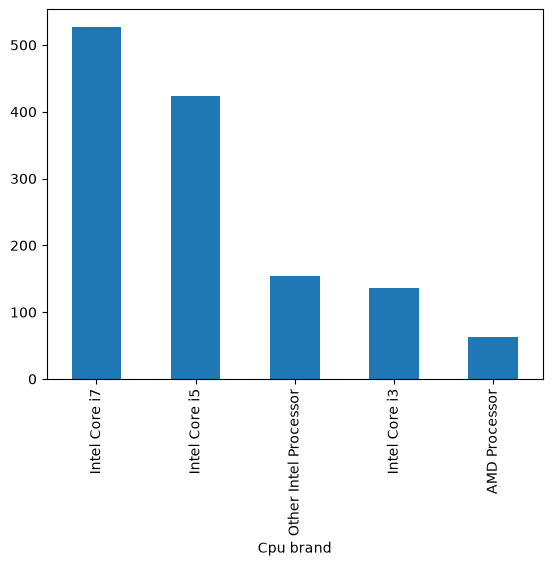

In [50]:
df['Cpu brand'].value_counts().plot(kind='bar')

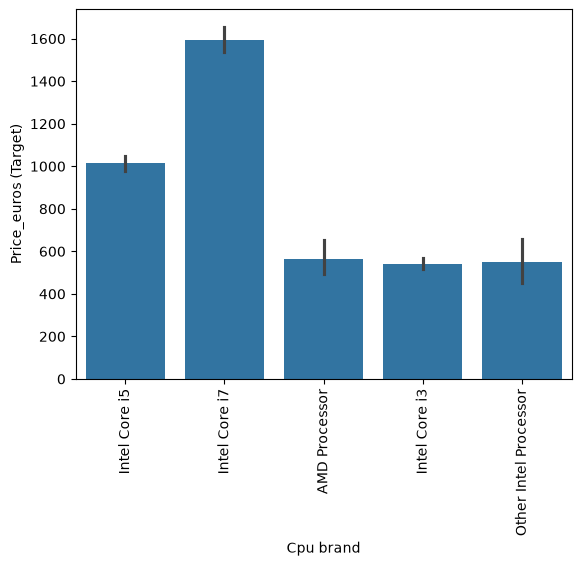

In [51]:
sns.barplot(x=df['Cpu brand'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

In [52]:
df.drop(columns=['Cpu'], inplace=True)

In [53]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand
0,1,Apple,MacBook Pro,Ultrabook,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5
1,2,Apple,Macbook Air,Ultrabook,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5
2,3,HP,250 G6,Notebook,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5
3,4,Apple,MacBook Pro,Ultrabook,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7
4,5,Apple,MacBook Pro,Ultrabook,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5


<Axes: xlabel='Ram'>

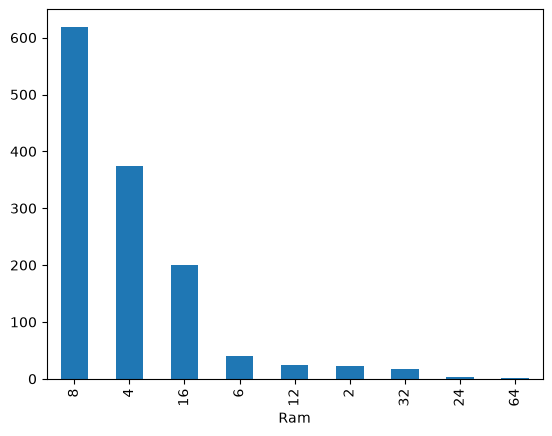

In [54]:
df['Ram'].value_counts().plot(kind='bar')

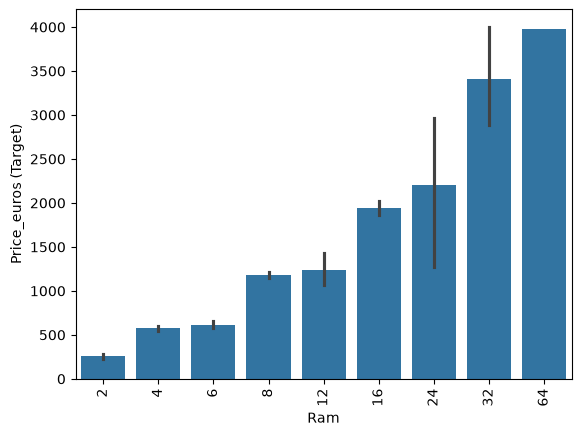

In [55]:
sns.barplot(x=df['Ram'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

In [56]:
df['Memory'].value_counts()

Memory
256GB SSD                        412
1TB HDD                          223
500GB HDD                        132
512GB SSD                        118
128GB SSD +  1TB HDD              94
128GB SSD                         76
256GB SSD +  1TB HDD              73
32GB Flash Storage                38
2TB HDD                           16
64GB Flash Storage                15
512GB SSD +  1TB HDD              14
1TB SSD                           14
256GB SSD +  2TB HDD              10
1.0TB Hybrid                       9
256GB Flash Storage                8
16GB Flash Storage                 7
32GB SSD                           6
180GB SSD                          5
128GB Flash Storage                4
16GB SSD                           3
512GB SSD +  2TB HDD               3
256GB SSD +  256GB SSD             2
256GB SSD +  500GB HDD             2
128GB SSD +  2TB HDD               2
1TB SSD +  1TB HDD                 2
512GB Flash Storage                2
64GB SSD                       

In [57]:
# Cleaning and processing the 'Memory' column
df['Memory'] = df['Memory'].astype(str).replace('\\.0', '', regex=True)
df['Memory'] = df['Memory'].str.replace('GB', '', regex=False)
df['Memory'] = df['Memory'].str.replace('TB', '000', regex=False)

# Split storage values and derive numeric storage features
new = df['Memory'].str.split('+', n=1, expand=True)
df['first'] = new[0].fillna('0').str.strip()
df['second'] = new[1].fillna('0').str.strip()
df['Layer1HDD'] = df['first'].str.contains('HDD', na=False).astype(int)
df['Layer1SSD'] = df['first'].str.contains('SSD', na=False).astype(int)
df['Layer1Hybrid'] = df['first'].str.contains('Hybrid', na=False).astype(int)
df['Layer1Flash_Storage'] = df['first'].str.contains('Flash Storage', na=False).astype(int)

df['first'] = pd.to_numeric(df['first'].str.replace(r'\\D', '', regex=True), errors='coerce').fillna(0).astype(int)
df['second'] = pd.to_numeric(df['second'].str.replace(r'\\D', '', regex=True), errors='coerce').fillna(0).astype(int)

df['HDD'] = df['first'] * df['Layer1HDD']
df['SSD'] = df['first'] * df['Layer1SSD']
df['Hybrid'] = df['first'] * df['Layer1Hybrid']
df['Flash_Storage'] = df['first'] * df['Layer1Flash_Storage']

df.drop(columns=['first', 'second', 'Layer1HDD', 'Layer1SSD', 'Layer1Hybrid', 'Layer1Flash_Storage'], inplace=True)

In [58]:
df.sample(5)

,laptop_ID,Company,Product,TypeName,Ram,Memory,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Hybrid,Flash_Storage
502,509,Lenovo,Yoga 920-13IKB,2 in 1 Convertible,8,256 SSD,Intel UHD Graphics 620,Windows 10,1.40,1599.00,1,1,158.482530,Intel Core i5,0,0,0,0
193,197,Lenovo,IdeaPad 320-17IKBR,Notebook,8,256 SSD,Nvidia GeForce MX150,No OS,2.80,698.00,0,0,106.113062,Intel Core i5,0,0,0,0
375,381,HP,15-bw003nv (A9-Series-9420/4GB/256GB/FHD/W10),Notebook,4,256 SSD,AMD Radeon R5,Windows 10,1.91,488.99,0,0,141.211998,AMD Processor,0,0,0,0
504,511,Lenovo,Chromebook N23,Netbook,4,16 SSD,Intel HD Graphics 400,Chrome OS,1.25,265.00,0,0,135.094211,Other Intel Processor,0,0,0,0
289,294,Lenovo,IdeaPad 320-15IKB,Notebook,8,1000 HDD,Nvidia GeForce 940MX,No OS,2.20,659.01,0,0,141.211998,Intel Core i7,0,0,0,0


In [59]:
df.drop(columns=['Memory'],inplace=True)

In [60]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Hybrid,Flash_Storage
0,1,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,0,0,0
1,2,Apple,Macbook Air,Ultrabook,8,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,0,0
2,3,HP,250 G6,Notebook,8,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,0,0,0
3,4,Apple,MacBook Pro,Ultrabook,16,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,0,0,0
4,5,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,0,0,0


In [61]:
df.corr(numeric_only=True)['Price_euros (Target)']

laptop_ID               0.067830
Ram                     0.743007
Weight                  0.210370
Price_euros (Target)    1.000000
Touchscreen             0.191226
Ips                     0.252208
ppi                     0.473487
HDD                          NaN
SSD                          NaN
Hybrid                       NaN
Flash_Storage                NaN
Name: Price_euros (Target), dtype: float64

In [62]:
df.drop(columns=['Hybrid','Flash_Storage'],inplace=True)

In [63]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD
0,1,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,0
1,2,Apple,Macbook Air,Ultrabook,8,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0
2,3,HP,250 G6,Notebook,8,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,0
3,4,Apple,MacBook Pro,Ultrabook,16,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,0
4,5,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,0


In [64]:
df['Gpu'].value_counts()

Gpu
Intel HD Graphics 620      281
Intel HD Graphics 520      185
Intel UHD Graphics 620      68
Nvidia GeForce GTX 1050     66
Nvidia GeForce GTX 1060     48
                          ... 
Nvidia Quadro M500M          1
AMD Radeon R7 M360           1
Nvidia Quadro M3000M         1
Nvidia GeForce 960M          1
ARM Mali T860 MP4            1
Name: count, Length: 110, dtype: int64

In [65]:
df['Gpu brand'] = df['Gpu'].apply(lambda x:x.split()[0])

In [66]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Gpu,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand
0,1,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,0,Intel
1,2,Apple,Macbook Air,Ultrabook,8,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,Intel
2,3,HP,250 G6,Notebook,8,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,0,Intel
3,4,Apple,MacBook Pro,Ultrabook,16,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,0,AMD
4,5,Apple,MacBook Pro,Ultrabook,8,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,0,Intel


In [67]:
df['Gpu brand'].value_counts()

Gpu brand
Intel     722
Nvidia    400
AMD       180
ARM         1
Name: count, dtype: int64

In [68]:
df=df[df['Gpu brand']!='ARM']

In [69]:
df['Gpu brand'].value_counts()

Gpu brand
Intel     722
Nvidia    400
AMD       180
Name: count, dtype: int64

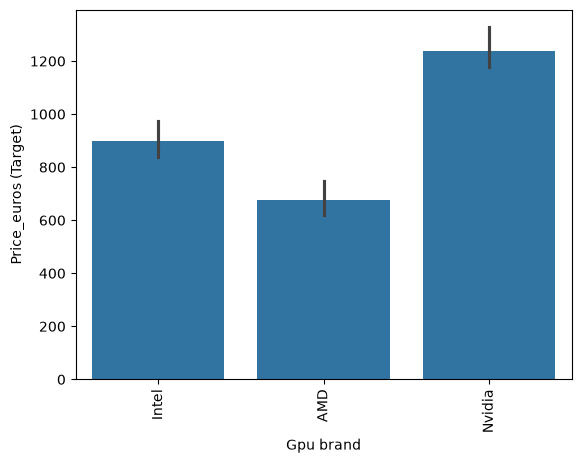

In [70]:
sns.barplot(x=df['Gpu brand'],y=df['Price_euros (Target)'],estimator=np.median)
plt.xticks(rotation='vertical')
plt.show()

In [71]:
df.drop(columns=['Gpu'],inplace=True)

In [72]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand
0,1,Apple,MacBook Pro,Ultrabook,8,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,0,Intel
1,2,Apple,Macbook Air,Ultrabook,8,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,Intel
2,3,HP,250 G6,Notebook,8,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,0,Intel
3,4,Apple,MacBook Pro,Ultrabook,16,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,0,AMD
4,5,Apple,MacBook Pro,Ultrabook,8,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,0,Intel


In [73]:
df['OpSys'].value_counts()

OpSys
Windows 10      1072
No OS             66
Linux             62
Windows 7         45
Chrome OS         26
macOS             13
Mac OS X           8
Windows 10 S       8
Android            2
Name: count, dtype: int64

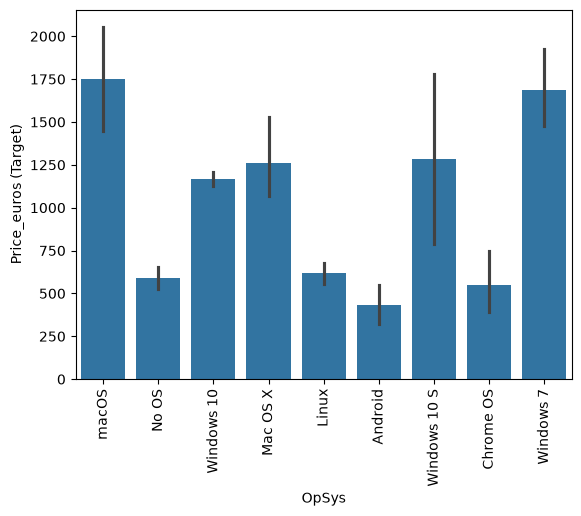

In [74]:
sns.barplot(x=df['OpSys'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

In [75]:
def cat_os(inp):
    if inp == 'Windows 10' or inp == 'Windows 7' or inp == 'Windows 10 S':
        return 'Windows'
    elif inp == 'macOS' or inp == 'Mac OS X':
        return 'Mac'
    else:
        return 'Others/No OS/Linux'

In [76]:
df['os']=df['OpSys'].apply(cat_os)

In [77]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,OpSys,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand,os
0,1,Apple,MacBook Pro,Ultrabook,8,macOS,1.37,1339.69,0,1,226.983005,Intel Core i5,0,0,Intel,Mac
1,2,Apple,Macbook Air,Ultrabook,8,macOS,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,Intel,Mac
2,3,HP,250 G6,Notebook,8,No OS,1.86,575.00,0,0,141.211998,Intel Core i5,0,0,Intel,Others/No OS/Linux
3,4,Apple,MacBook Pro,Ultrabook,16,macOS,1.83,2537.45,0,1,220.534624,Intel Core i7,0,0,AMD,Mac
4,5,Apple,MacBook Pro,Ultrabook,8,macOS,1.37,1803.60,0,1,226.983005,Intel Core i5,0,0,Intel,Mac


In [78]:
df.drop(columns=['OpSys'],inplace=True)

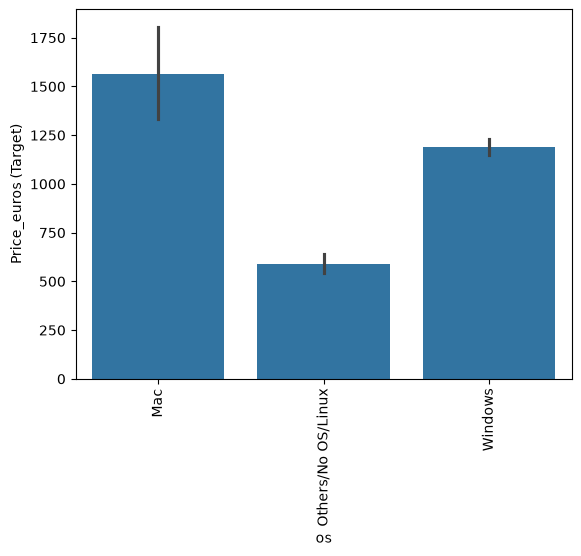

In [79]:
sns.barplot(x=df['os'],y=df['Price_euros (Target)'])
plt.xticks(rotation='vertical')
plt.show()

C:\Users\pc\AppData\Local\Temp\ipykernel_19312\1125578356.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Weight'])


<Axes: xlabel='Weight', ylabel='Density'>

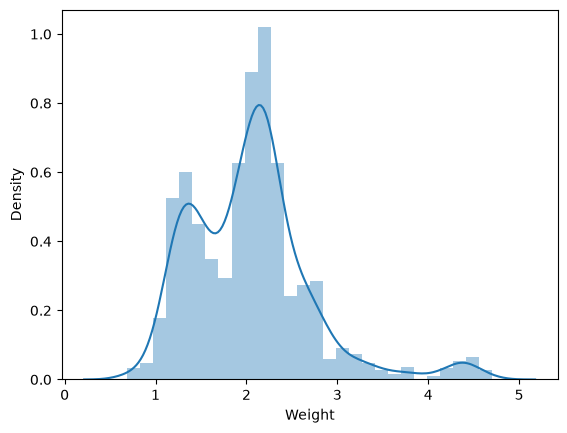

In [80]:
sns.distplot(df['Weight'])

<Axes: xlabel='Weight', ylabel='Price_euros (Target)'>

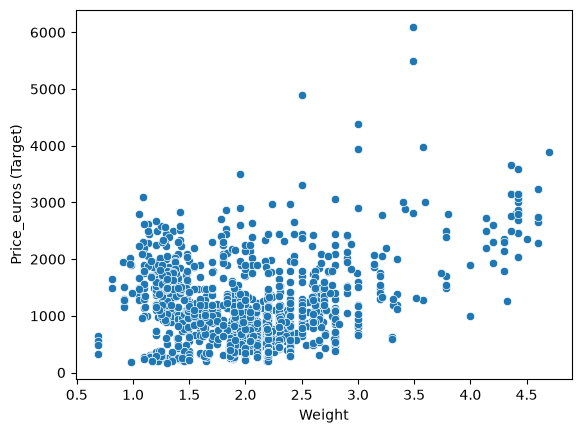

In [81]:
sns.scatterplot(x=df['Weight'],y=df['Price_euros (Target)'])

In [82]:
df.corr(numeric_only=True)['Price_euros (Target)']

laptop_ID               0.068632
Ram                     0.742905
Weight                  0.209867
Price_euros (Target)    1.000000
Touchscreen             0.192917
Ips                     0.253320
ppi                     0.475368
HDD                          NaN
SSD                          NaN
Name: Price_euros (Target), dtype: float64

C:\Users\pc\AppData\Local\Temp\ipykernel_19312\1093788652.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Price_euros (Target)'])


<Axes: xlabel='Price_euros (Target)', ylabel='Density'>

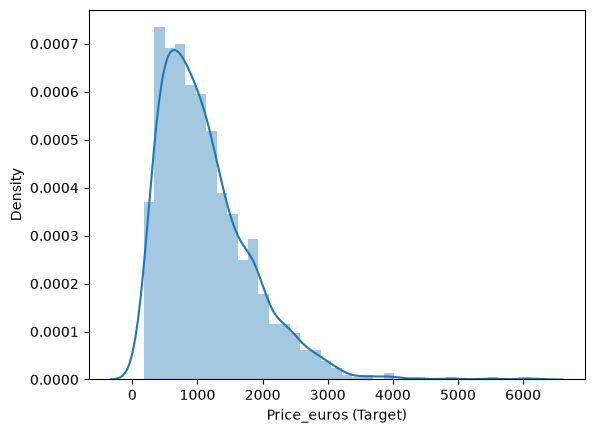

In [83]:
sns.distplot(df['Price_euros (Target)'])

C:\Users\pc\AppData\Local\Temp\ipykernel_19312\684539983.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(np.log(df['Price_euros (Target)']))


<Axes: xlabel='Price_euros (Target)', ylabel='Density'>

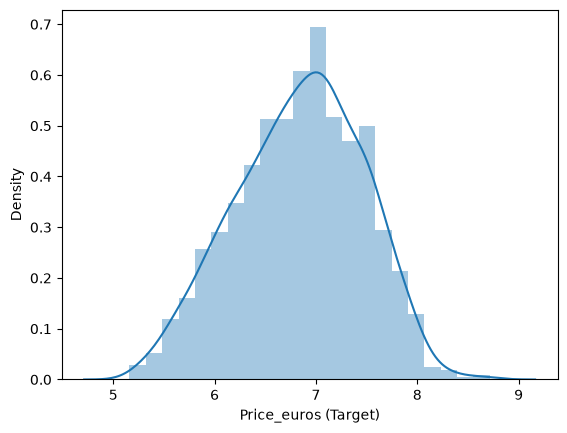

In [84]:
sns.distplot(np.log(df['Price_euros (Target)']))

In [85]:
df.info()

<class 'pandas.DataFrame'>
Index: 1302 entries, 0 to 1302
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   laptop_ID             1302 non-null   int64  
 1   Company               1302 non-null   str    
 2   Product               1302 non-null   str    
 3   TypeName              1302 non-null   str    
 4   Ram                   1302 non-null   int64  
 5   Weight                1302 non-null   float64
 6   Price_euros (Target)  1302 non-null   float64
 7   Touchscreen           1302 non-null   int64  
 8   Ips                   1302 non-null   int64  
 9   ppi                   1302 non-null   float64
 10  Cpu brand             1302 non-null   str    
 11  HDD                   1302 non-null   int64  
 12  SSD                   1302 non-null   int64  
 13  Gpu brand             1302 non-null   str    
 14  os                    1302 non-null   str    
dtypes: float64(3), int64(6), str(6)
memor

In [86]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

# Linear Regression:

In [87]:
X = df.drop(columns='Price_euros (Target)')  # Features
y = df['Price_euros (Target)']  # Target variable

# Identify categorical features
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Define a column transformer for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'  # Leave other columns unchanged
)

# Create the model pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
# Evaluate the model
score = model.score(X_test, y_test)
print(f"Model R^2 score: {score}")
print(f"Mean Abs Error: {mean_absolute_error(y_test,y_pred)}")

C:\Users\pc\AppData\Local\Temp\ipykernel_19312\497022043.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object']).columns.tolist()


Model R^2 score: 0.7879308980835883
Mean Abs Error: 205.23482839914283


# KNN:

In [88]:
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Define a column transformer for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'  # Leave other columns unchanged
)

# Create the model pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', KNeighborsRegressor(n_neighbors=3))  # Use KNN instead of LinearRegression
])

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Evaluate the model
score = model.score(X_test, y_test)  # R^2 score
print(f"Model R^2 score: {score}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred)}")

Model R^2 score: 0.3582132209863532
Mean Absolute Error: 388.54169859514684


C:\Users\pc\AppData\Local\Temp\ipykernel_19312\3383190230.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object']).columns.tolist()


# Random Forest:

In [89]:
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Define a column transformer for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'  # Leave other columns unchanged
)

# Create the model pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))  # Use Random Forest
])

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Evaluate the model
score = model.score(X_test, y_test)  # R^2 score
print(f"Model R^2 score: {score}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred)}")

C:\Users\pc\AppData\Local\Temp\ipykernel_19312\3261412510.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object']).columns.tolist()


Model R^2 score: 0.8049310451333114
Mean Absolute Error: 197.87407969348655


In [90]:
import pandas as pd

# Example laptop specifications with the same raw feature names used for training
laptop_specs = {
    'laptop_ID': [1],
    'Company': ['Dell'],
    'Product': ['Inspiron'],
    'TypeName': ['Notebook'],
    'Ram': [8],
    'Weight': [2.5],
    'Touchscreen': [0],
    'Ips': [1],
    'ppi': [141.211998],
    'Cpu brand': ['Intel Core i5'],
    'HDD': [0],
    'SSD': [256],
    'Gpu brand': ['Intel'],
    'os': ['Windows']
}

input_data = pd.DataFrame(laptop_specs)

# Add any training columns that are absent, then use the exact training order.
for column in X.columns:
    if column not in input_data.columns:
        input_data[column] = '' if column in categorical_features else 0
input_data = input_data[X.columns]

predicted_price = model.predict(input_data)
print(f"Predicted Laptop Price: {predicted_price[0]}")


Predicted Laptop Price: 898.9622


In [91]:
df.head()

,laptop_ID,Company,Product,TypeName,Ram,Weight,Price_euros (Target),Touchscreen,Ips,ppi,Cpu brand,HDD,SSD,Gpu brand,os
0,1,Apple,MacBook Pro,Ultrabook,8,1.37,1339.69,0,1,226.983005,Intel Core i5,0,0,Intel,Mac
1,2,Apple,Macbook Air,Ultrabook,8,1.34,898.94,0,0,127.677940,Intel Core i5,0,0,Intel,Mac
2,3,HP,250 G6,Notebook,8,1.86,575.00,0,0,141.211998,Intel Core i5,0,0,Intel,Others/No OS/Linux
3,4,Apple,MacBook Pro,Ultrabook,16,1.83,2537.45,0,1,220.534624,Intel Core i7,0,0,AMD,Mac
4,5,Apple,MacBook Pro,Ultrabook,8,1.37,1803.60,0,1,226.983005,Intel Core i5,0,0,Intel,Mac


In [1]:
# Improved laptop price prediction pipeline
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor

raw = pd.read_csv('Laptop.csv', encoding='latin1')

def number_from_text(series):
    return pd.to_numeric(series.astype(str).str.extract(r'(\d+(?:\.\d+)?)')[0], errors='coerce')

raw['Ram'] = number_from_text(raw['Ram'])
raw['Weight'] = number_from_text(raw['Weight'])
raw['Touchscreen'] = raw['ScreenResolution'].str.contains('Touchscreen', na=False).astype(int)
raw['Ips'] = raw['ScreenResolution'].str.contains('IPS', na=False).astype(int)
resolution = raw['ScreenResolution'].str.extract(r'(?P<X_res>\d+)x(?P<Y_res>\d+)').astype(float)
raw['X_res'] = resolution['X_res']
raw['Y_res'] = resolution['Y_res']
raw['ppi'] = np.sqrt(raw['X_res'] ** 2 + raw['Y_res'] ** 2) / raw['Inches']

raw['Cpu brand'] = raw['Cpu'].str.extract(r'(Intel Core i[3579]|AMD|Intel|Apple|Other)')[0].fillna('Other')
raw['Cpu speed'] = number_from_text(raw['Cpu'].str.extract(r'(\d+(?:\.\d+)?)GHz')[0])
raw['Cpu model'] = raw['Cpu'].str.replace(r'\s+\d+(?:\.\d+)?GHz', '', regex=True)
raw['Gpu brand'] = raw['Gpu'].str.split().str[0]
raw['Gpu model'] = raw['Gpu'].str.replace(r'^(Intel|AMD|Nvidia)\s+', '', regex=True)
raw['os'] = raw['OpSys'].map(lambda value: 'Windows' if str(value).startswith('Windows') else ('Mac' if value in ['macOS', 'Mac OS X'] else 'Other'))

memory_parts = raw['Memory'].str.split('+', n=1, expand=True).fillna('0')
raw['SSD'] = 0
raw['HDD'] = 0
raw['Hybrid'] = 0
raw['Flash_Storage'] = 0
for column in memory_parts.columns:
    capacity = number_from_text(memory_parts[column]).fillna(0)
    raw['SSD'] += capacity * memory_parts[column].str.contains('SSD', case=False, na=False).astype(int)
    raw['HDD'] += capacity * memory_parts[column].str.contains('HDD', case=False, na=False).astype(int)
    raw['Hybrid'] += capacity * memory_parts[column].str.contains('Hybrid', case=False, na=False).astype(int)
    raw['Flash_Storage'] += capacity * memory_parts[column].str.contains('Flash Storage', case=False, na=False).astype(int)

raw = raw[raw['Gpu brand'] != 'ARM'].copy()
y_improved = raw.pop('Price_euros (Target)')
X_improved = raw.drop(columns=['laptop_ID', 'ScreenResolution', 'Cpu', 'Gpu', 'OpSys', 'Memory', 'X_res', 'Y_res'])
categorical_improved = X_improved.select_dtypes(include=['object']).columns.tolist()
preprocessor_improved = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_improved)
], remainder='passthrough')

models = {
    'Extra Trees': ExtraTreesRegressor(n_estimators=600, max_features=0.85, min_samples_leaf=1, random_state=42, n_jobs=-1),
    'Random Forest': RandomForestRegressor(n_estimators=600, max_features=0.85, min_samples_leaf=1, random_state=42, n_jobs=-1)
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}
for name, estimator in models.items():
    candidate = Pipeline([('preprocessor', preprocessor_improved), ('regressor', estimator)])
    scores = cross_validate(candidate, X_improved, y_improved, cv=cv, scoring=['r2', 'neg_mean_absolute_error'])
    results[name] = -scores['test_neg_mean_absolute_error'].mean()
    print(f'{name}: R2={scores["test_r2"].mean():.3f}, MAE=€{results[name]:.2f}')

best_name = min(results, key=results.get)
best_model = Pipeline([
    ('preprocessor', preprocessor_improved),
    ('regressor', models[best_name])
])
best_model.fit(X_improved, y_improved)
print(f'Final model selected by cross-validated MAE: {best_name}')


C:\Users\pc\AppData\Local\Temp\ipykernel_26468\2697116549.py:46: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_improved = X_improved.select_dtypes(include=['object']).columns.tolist()


Extra Trees: R2=0.821, MAE=€171.75
Random Forest: R2=0.849, MAE=€167.96
Final model selected by cross-validated MAE: Random Forest


In [2]:
# CatBoost comparison for mixed laptop features
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error

catboost_data = X_improved.copy()
catboost_columns = catboost_data.select_dtypes(include=['object']).columns.tolist()
for column in catboost_columns:
    catboost_data[column] = catboost_data[column].fillna('Unknown').astype(str)
catboost_target = y_improved.reset_index(drop=True)
catboost_data = catboost_data.reset_index(drop=True)

catboost_r2 = []
catboost_mae = []
for train_index, validation_index in cv.split(catboost_data):
    catboost_model = CatBoostRegressor(
        iterations=1200,
        depth=7,
        learning_rate=0.03,
        loss_function='RMSE',
        random_seed=42,
        verbose=False
    )
    catboost_model.fit(
        catboost_data.iloc[train_index],
        catboost_target.iloc[train_index],
        cat_features=catboost_columns
    )
    validation_prediction = catboost_model.predict(catboost_data.iloc[validation_index])
    catboost_r2.append(r2_score(catboost_target.iloc[validation_index], validation_prediction))
    catboost_mae.append(mean_absolute_error(catboost_target.iloc[validation_index], validation_prediction))

print(f'CatBoost: R2={np.mean(catboost_r2):.3f}, MAE=€{np.mean(catboost_mae):.2f}')
catboost_final = CatBoostRegressor(
    iterations=1200,
    depth=7,
    learning_rate=0.03,
    loss_function='RMSE',
    random_seed=42,
    verbose=False
)
catboost_final.fit(catboost_data, catboost_target, cat_features=catboost_columns)


C:\Users\pc\AppData\Local\Temp\ipykernel_26468\1971720914.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  catboost_columns = catboost_data.select_dtypes(include=['object']).columns.tolist()


CatBoost: R2=0.849, MAE=€158.08


CatBoostRegressor(depth=7, iterations=1200, learning_rate=0.03, loss_function='RMSE', random_seed=42, verbose=False)